# Student Dropout Prediction

Predict whether a higher-education student will **Graduate**, **Drop out**, or still be **Enrolled** at the end of the normal course duration,
using the UCI *Predict Students' Dropout and Academic Success* dataset (4,424 students, 36 features).

**Workflow:** load & check → EDA → stratified train/test split → compare 5 models with cross-validation → tune the best two →
evaluate on the held-out test set → interpret → early-warning variant → save the model for the Streamlit app.

The main metric is **macro-F1** (the three classes are imbalanced, and the minority *Enrolled* class matters as much as the others).
All preprocessing lives in `src/features.py` so the app applies exactly the same steps.

In [1]:
import sys
import json
import platform
from datetime import date
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(PROJECT_ROOT))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import xgboost
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score, balanced_accuracy_score,
                             classification_report, f1_score, recall_score, roc_auc_score)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_validate, train_test_split
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

from src.features import (BINARY, CLASS_NAMES, COURSE_NAMES, FIGURES_DIR, MODELS_DIR, NOMINAL, SEM1, SEM2, TARGET,
                          build_pipeline, input_columns, load_raw, numeric_columns)

RANDOM_STATE = 42
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
CLASS_COLORS = {"Dropout": "#d62728", "Enrolled": "#ff7f0e", "Graduate": "#2ca02c"}


def savefig(name):
    plt.savefig(FIGURES_DIR / f"{name}.png", dpi=120, bbox_inches="tight")


print(f"Python {platform.python_version()} | pandas {pd.__version__} | scikit-learn {sklearn.__version__} | xgboost {xgboost.__version__}")

Python 3.13.14 | pandas 2.3.3 | scikit-learn 1.8.0 | xgboost 3.4.1


## 1. Load and sanity-check the data

In [2]:
df = load_raw()
print("Shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
df.head()

Shape: (4424, 37)
Missing values: 0
Duplicate rows: 0


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [3]:
target_counts = df[TARGET].value_counts()
pd.DataFrame({"students": target_counts, "share": (target_counts / len(df)).round(3)})

,students,share
Target,,
Graduate,2209,0.499
Dropout,1421,0.321
Enrolled,794,0.179


## 2. Exploratory data analysis

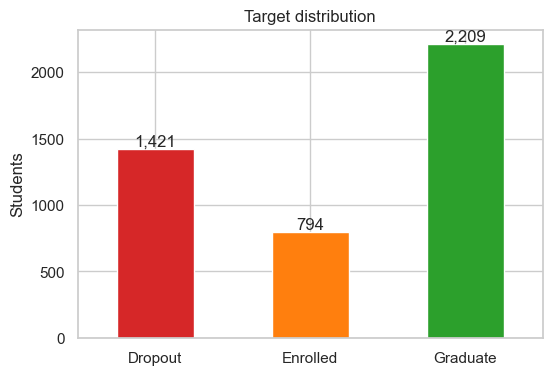

In [4]:
ax = target_counts.reindex(CLASS_NAMES).plot.bar(color=[CLASS_COLORS[c] for c in CLASS_NAMES], figsize=(6, 4), rot=0)
ax.set(title="Target distribution", ylabel="Students", xlabel="")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
savefig("01_target_distribution")
plt.show()

### Outcome by financial and personal flags

In [5]:
flags = ["Tuition fees up to date", "Debtor", "Scholarship holder", "Gender", "Displaced", "International"]
rows = []
for col in flags:
    ct = pd.crosstab(df[col], df[TARGET], normalize="index")
    for val, r in ct.iterrows():
        rows.append({"feature": col, "value": val, "n": int((df[col] == val).sum()), **r.round(3).to_dict()})
flag_table = pd.DataFrame(rows)
flag_table

,feature,value,n,Dropout,Enrolled,Graduate
0,Tuition fees up to date,0,528,0.866,0.080,0.055
1,Tuition fees up to date,1,3896,0.247,0.193,0.560
2,Debtor,0,3921,0.283,0.180,0.538
3,Debtor,1,503,0.620,0.179,0.201
4,Scholarship holder,0,3325,0.387,0.200,0.413
5,Scholarship holder,1,1099,0.122,0.118,0.760
6,Gender,0,2868,0.251,0.170,0.579
7,Gender,1,1556,0.451,0.197,0.352
8,Displaced,0,1998,0.376,0.181,0.443
9,Displaced,1,2426,0.276,0.178,0.546


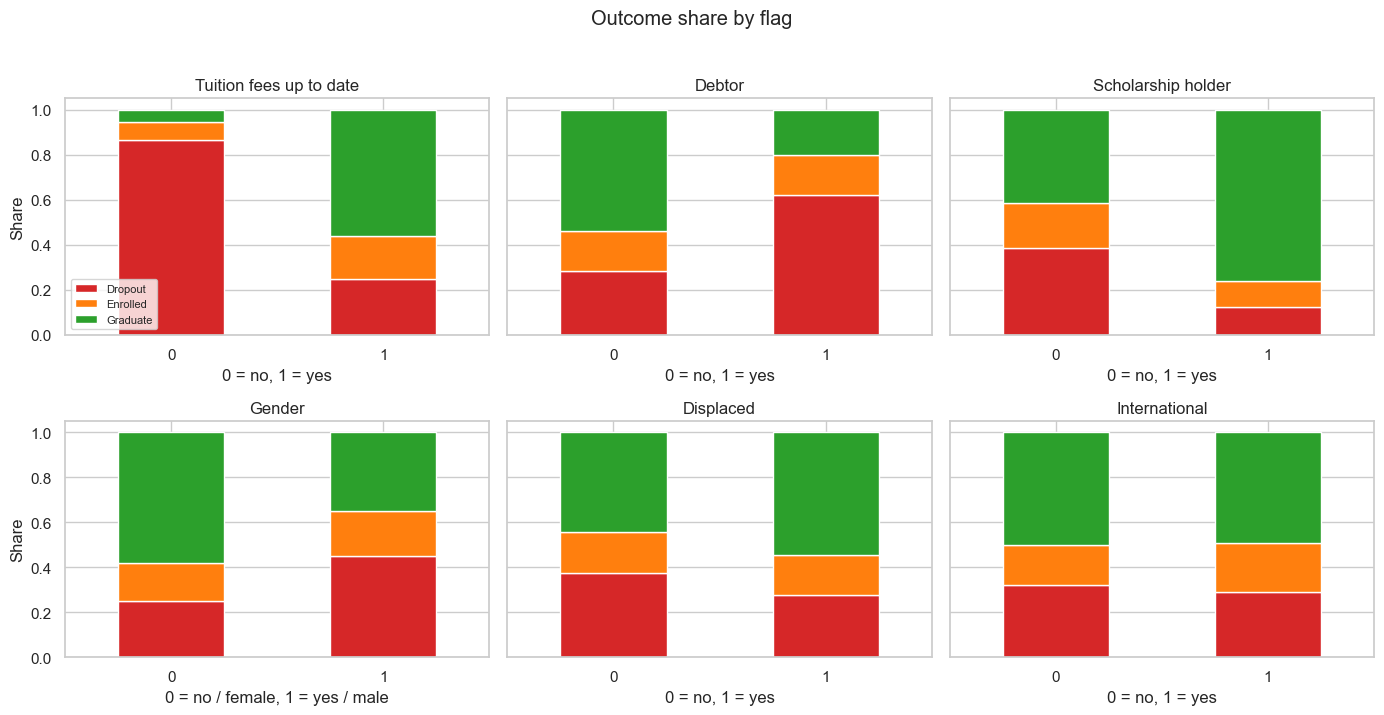

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharey=True)
for ax, col in zip(axes.ravel(), flags):
    ct = pd.crosstab(df[col], df[TARGET], normalize="index")[CLASS_NAMES]
    ct.plot.bar(stacked=True, ax=ax, color=[CLASS_COLORS[c] for c in CLASS_NAMES], legend=False, rot=0)
    ax.set(title=col, xlabel="0 = no / female, 1 = yes / male" if col == "Gender" else "0 = no, 1 = yes", ylabel="Share")
axes[0, 0].legend(loc="lower left", fontsize=8)
fig.suptitle("Outcome share by flag", y=1.02)
plt.tight_layout()
savefig("02_outcome_by_flags")
plt.show()

### Dropout rate by course

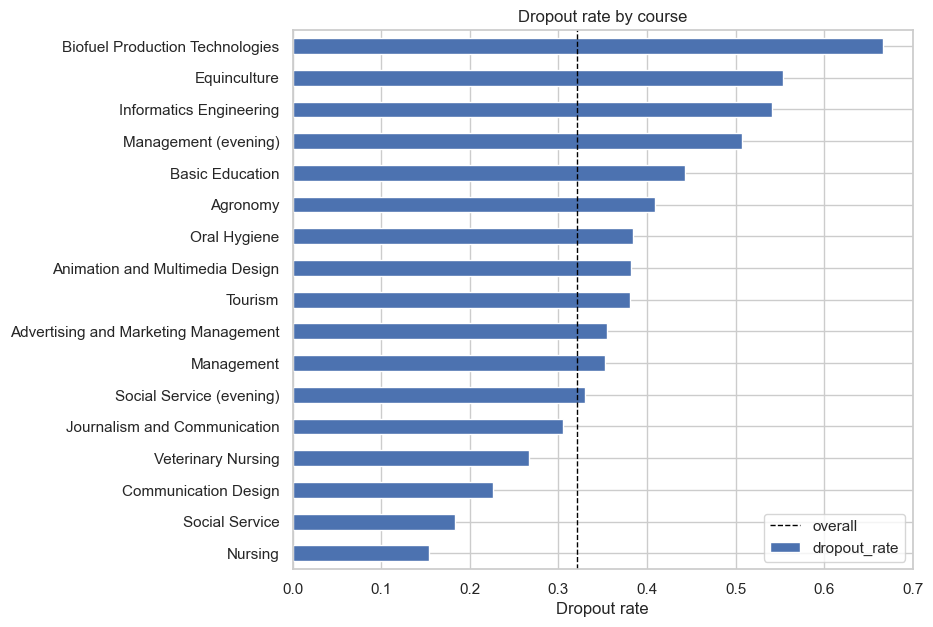

,students,dropout_rate
course,,
Biofuel Production Technologies,12,0.667
Equinculture,141,0.553
Informatics Engineering,170,0.541
Management (evening),268,0.507
Basic Education,192,0.443
Agronomy,210,0.410
Oral Hygiene,86,0.384
Animation and Multimedia Design,215,0.381
Tourism,252,0.381


In [7]:
course = (df.assign(course=df["Course"].map(COURSE_NAMES), dropout=df[TARGET].eq("Dropout"))
            .groupby("course").agg(students=("dropout", "size"), dropout_rate=("dropout", "mean"))
            .sort_values("dropout_rate"))
ax = course["dropout_rate"].plot.barh(figsize=(8, 7), color="#4c72b0")
ax.axvline(df[TARGET].eq("Dropout").mean(), color="black", ls="--", lw=1, label="overall")
ax.set(title="Dropout rate by course", xlabel="Dropout rate", ylabel="")
ax.legend()
savefig("03_dropout_by_course")
plt.show()
course.sort_values("dropout_rate", ascending=False).round(3)

### Numeric features by outcome

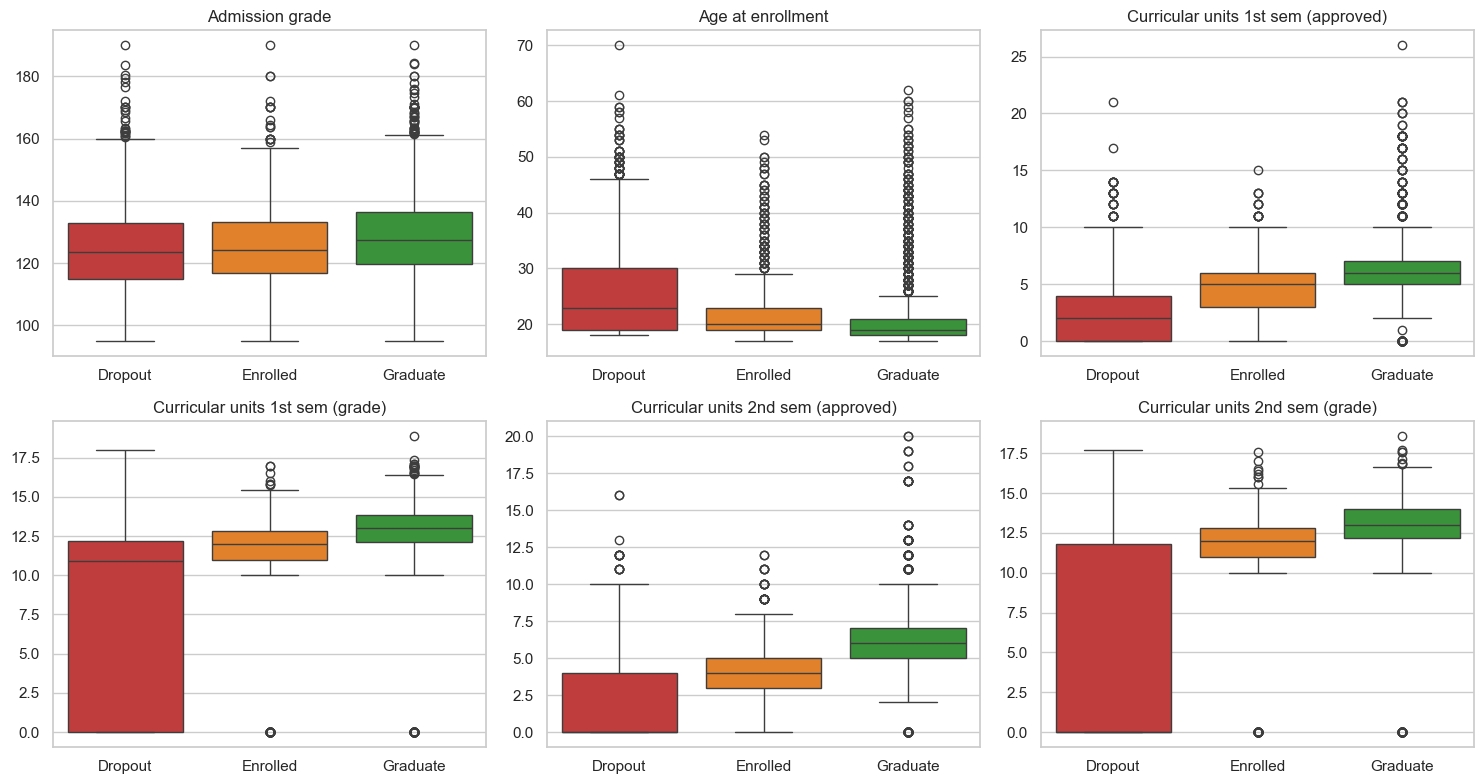

Target,Dropout,Enrolled,Graduate
Admission grade,123.60,124.1,127.4
Age at enrollment,23.00,20.0,19.0
Curricular units 1st sem (approved),2.00,5.0,6.0
Curricular units 1st sem (grade),10.93,12.0,13.0
Curricular units 2nd sem (approved),0.00,4.0,6.0
Curricular units 2nd sem (grade),0.00,12.0,13.0


In [8]:
num_show = ["Admission grade", "Age at enrollment", "Curricular units 1st sem (approved)", "Curricular units 1st sem (grade)",
            "Curricular units 2nd sem (approved)", "Curricular units 2nd sem (grade)"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), num_show):
    sns.boxplot(data=df, x=TARGET, y=col, order=CLASS_NAMES, hue=TARGET, palette=CLASS_COLORS, ax=ax, legend=False)
    ax.set(title=col, xlabel="", ylabel="")
plt.tight_layout()
savefig("04_numeric_by_outcome")
plt.show()
df.groupby(TARGET)[num_show].median().T.round(2)

In [9]:
zero_units = (df["Curricular units 1st sem (enrolled)"] == 0)
print(f"Students with 0 units enrolled in 1st sem: {zero_units.sum()} ({zero_units.mean():.1%})")
no_pass = df["Curricular units 2nd sem (approved)"] == 0
print(f"Students passing 0 units in 2nd sem: {no_pass.sum()} -> outcome mix:")
print(df.loc[no_pass, TARGET].value_counts(normalize=True).round(3).to_string())

Students with 0 units enrolled in 1st sem: 180 (4.1%)
Students passing 0 units in 2nd sem: 870 -> outcome mix:
Target
Dropout     0.836
Graduate    0.086
Enrolled    0.078


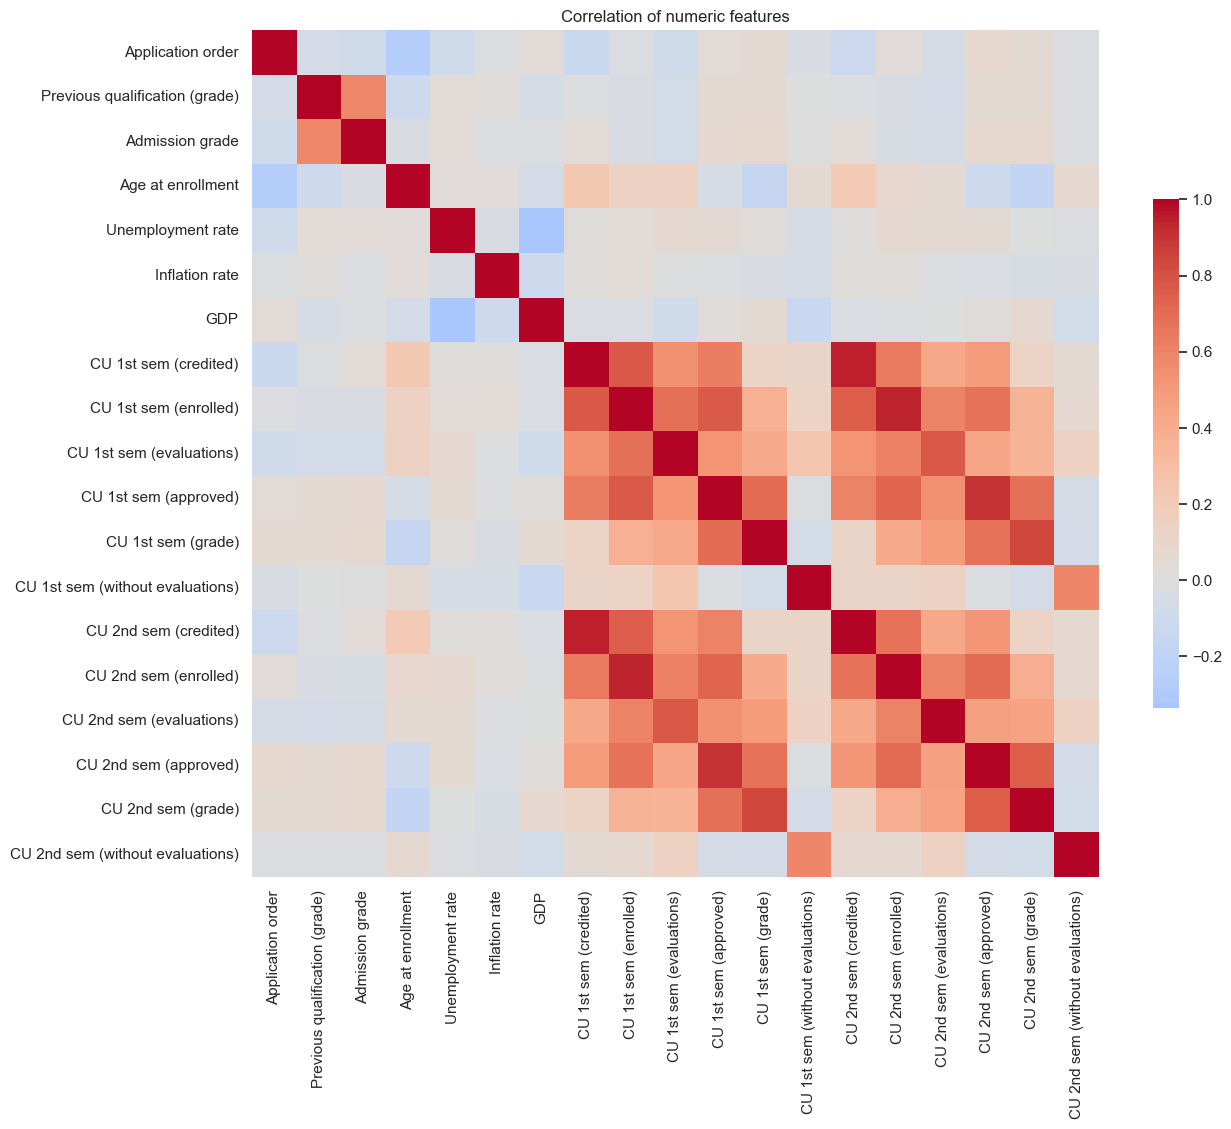

In [10]:
num_cols = [c for c in numeric_columns() if c in df.columns]
corr = df[num_cols].corr()
plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": 0.6},
            xticklabels=[c.replace("Curricular units ", "CU ") for c in num_cols],
            yticklabels=[c.replace("Curricular units ", "CU ") for c in num_cols])
plt.title("Correlation of numeric features")
savefig("05_correlation_heatmap")
plt.show()

**EDA takeaways** (numbers printed above):
- Students whose tuition fees are *not* up to date, and debtors, drop out far more often; scholarship holders far less.
- Graduates pass many more curricular units and have higher semester grades; most students who pass 0 units in the 2nd semester drop out.
- Dropout rate differs strongly by course.
- 1st- and 2nd-semester measures are highly correlated (tree models cope well; logistic regression is regularised).

## 3. Train / test split

In [11]:
X = df[input_columns()]
y = df[TARGET].map({c: i for i, c in enumerate(CLASS_NAMES)}).to_numpy()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Train class shares:", np.round(np.bincount(y_train) / len(y_train), 3), "order:", CLASS_NAMES)

Train: (3539, 36) Test: (885, 36)
Train class shares: [0.321 0.179 0.499] order: ['Dropout', 'Enrolled', 'Graduate']


## 4. Model comparison (5-fold stratified cross-validation on the training set)

Class imbalance is handled with `class_weight="balanced"` (Logistic Regression, Random Forest, HistGradientBoosting)
or balanced per-sample weights (XGBoost, which has no `class_weight`). The Dummy model always predicts the majority class and is the floor to beat.

In [12]:
models = {
    "Dummy (majority class)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=3000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=400, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    "XGBoost": XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                             eval_metric="mlogloss", random_state=RANDOM_STATE, n_jobs=1),
}


def fit_params(name, y_fit):
    """XGBoost gets balanced sample weights; the others use class_weight."""
    return {"model__sample_weight": compute_sample_weight("balanced", y_fit)} if name == "XGBoost" else {}


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"macro_f1": "f1_macro", "balanced_accuracy": "balanced_accuracy", "accuracy": "accuracy"}

cv_rows = []
for name, model in models.items():
    res = cross_validate(build_pipeline(model), X_train, y_train, cv=cv, scoring=scoring,
                         params=fit_params(name, y_train), n_jobs=-1)
    cv_rows.append({"model": name,
                    **{f"{m}_mean": res[f"test_{m}"].mean() for m in scoring},
                    **{f"{m}_std": res[f"test_{m}"].std() for m in scoring},
                    "fit_seconds": res["fit_time"].mean()})
cv_results = pd.DataFrame(cv_rows).set_index("model").sort_values("macro_f1_mean", ascending=False)
cv_results.round(3)

,macro_f1_mean,balanced_accuracy_mean,accuracy_mean,macro_f1_std,balanced_accuracy_std,accuracy_std,fit_seconds
model,,,,,,,
XGBoost,0.738,0.742,0.780,0.009,0.009,0.008,1.123
Hist Gradient Boosting,0.725,0.720,0.780,0.014,0.014,0.011,1.464
Logistic Regression,0.711,0.719,0.752,0.014,0.015,0.014,0.102
Random Forest,0.693,0.683,0.775,0.020,0.018,0.011,1.252
Dummy (majority class),0.222,0.333,0.499,0.000,0.000,0.001,0.014


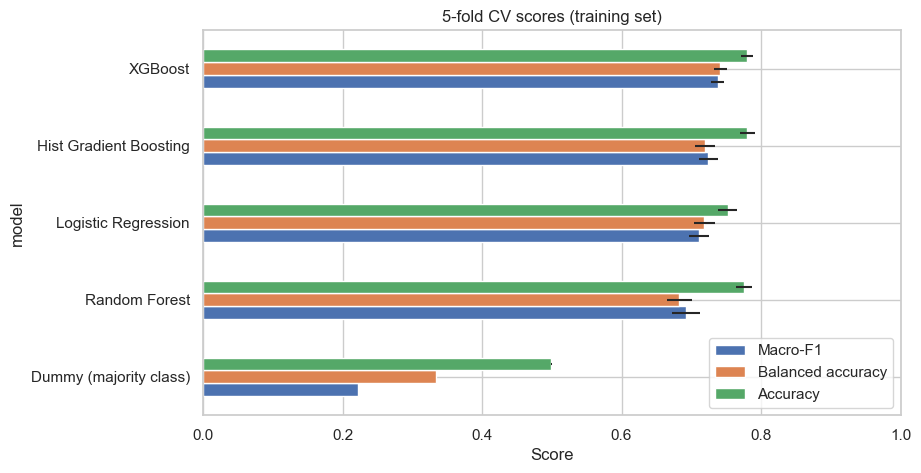

In [13]:
ax = cv_results[["macro_f1_mean", "balanced_accuracy_mean", "accuracy_mean"]].iloc[::-1].plot.barh(
    xerr=cv_results[["macro_f1_std", "balanced_accuracy_std", "accuracy_std"]].iloc[::-1].values.T, figsize=(9, 5))
ax.set(title="5-fold CV scores (training set)", xlabel="Score", xlim=(0, 1))
ax.legend(["Macro-F1", "Balanced accuracy", "Accuracy"], loc="lower right")
savefig("06_model_comparison")
plt.show()

## 5. Hyper-parameter tuning

`RandomizedSearchCV` (40 random configurations × 5 folds, optimising macro-F1) for the two best models from the comparison.

In [14]:
search_spaces = {
    "Logistic Regression": {"model__C": loguniform(1e-3, 1e2)},
    "Random Forest": {"model__n_estimators": randint(200, 800), "model__max_depth": [None, 8, 12, 16, 24],
                      "model__min_samples_leaf": randint(1, 10), "model__max_features": ["sqrt", 0.3, 0.5]},
    "Hist Gradient Boosting": {"model__learning_rate": loguniform(0.01, 0.3), "model__max_iter": randint(100, 600),
                               "model__max_leaf_nodes": randint(8, 64), "model__min_samples_leaf": randint(10, 60),
                               "model__l2_regularization": loguniform(1e-4, 10)},
    "XGBoost": {"model__n_estimators": randint(200, 800), "model__learning_rate": loguniform(0.01, 0.2),
                "model__max_depth": randint(3, 8), "model__subsample": uniform(0.6, 0.4),
                "model__colsample_bytree": uniform(0.5, 0.5), "model__min_child_weight": randint(1, 10),
                "model__reg_lambda": loguniform(0.1, 10)},
}

to_tune = [m for m in cv_results.index if m in search_spaces][:2]
print("Tuning:", to_tune)

searches = {}
for name in to_tune:
    search = RandomizedSearchCV(build_pipeline(clone(models[name])), search_spaces[name], n_iter=40, scoring="f1_macro",
                                cv=cv, n_jobs=-1, random_state=RANDOM_STATE)
    search.fit(X_train, y_train, **fit_params(name, y_train))
    searches[name] = search
    print(f"{name}: default CV macro-F1 {cv_results.loc[name, 'macro_f1_mean']:.4f} -> tuned {search.best_score_:.4f}")
    print("   best params:", {k.replace('model__', ''): (round(float(v), 4) if isinstance(v, float) else v) for k, v in search.best_params_.items()})

best_name = max(searches, key=lambda n: searches[n].best_score_)
best_search = searches[best_name]
final_model = best_search.best_estimator_
print("\nSelected model:", best_name)

Tuning: ['XGBoost', 'Hist Gradient Boosting']


XGBoost: default CV macro-F1 0.7378 -> tuned 0.7411
   best params: {'colsample_bytree': 0.9316, 'learning_rate': 0.0647, 'max_depth': 4, 'min_child_weight': 1, 'n_estimators': 247, 'reg_lambda': 0.5516, 'subsample': 0.8675}


Hist Gradient Boosting: default CV macro-F1 0.7245 -> tuned 0.7375
   best params: {'l2_regularization': 0.0094, 'learning_rate': 0.0271, 'max_iter': 162, 'max_leaf_nodes': 18, 'min_samples_leaf': 26}

Selected model: XGBoost


## 6. Final evaluation on the held-out test set

In [15]:
y_pred = final_model.predict(X_test)
y_proba = final_model.predict_proba(X_test)
baseline_pred = build_pipeline(models["Dummy (majority class)"]).fit(X_train, y_train).predict(X_test)

test_metrics = {
    "macro_f1": f1_score(y_test, y_pred, average="macro"),
    "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
    "accuracy": accuracy_score(y_test, y_pred),
    "roc_auc_ovr_macro": roc_auc_score(y_test, y_proba, multi_class="ovr", average="macro"),
}
baseline_metrics = {"macro_f1": f1_score(y_test, baseline_pred, average="macro"),
                    "accuracy": accuracy_score(y_test, baseline_pred)}
print(f"{best_name} on test:", {k: round(v, 4) for k, v in test_metrics.items()})
print("Dummy baseline on test:", {k: round(v, 4) for k, v in baseline_metrics.items()})
print()
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=3))
report = classification_report(y_test, y_pred, target_names=CLASS_NAMES, output_dict=True)

XGBoost on test: {'macro_f1': 0.7049, 'balanced_accuracy': 0.7148, 'accuracy': 0.7435, 'roc_auc_ovr_macro': 0.8877}
Dummy baseline on test: {'macro_f1': 0.2221, 'accuracy': 0.4994}

              precision    recall  f1-score   support

     Dropout      0.817     0.708     0.758       284
    Enrolled      0.450     0.629     0.525       159
    Graduate      0.856     0.808     0.831       442

    accuracy                          0.744       885
   macro avg      0.708     0.715     0.705       885
weighted avg      0.771     0.744     0.753       885



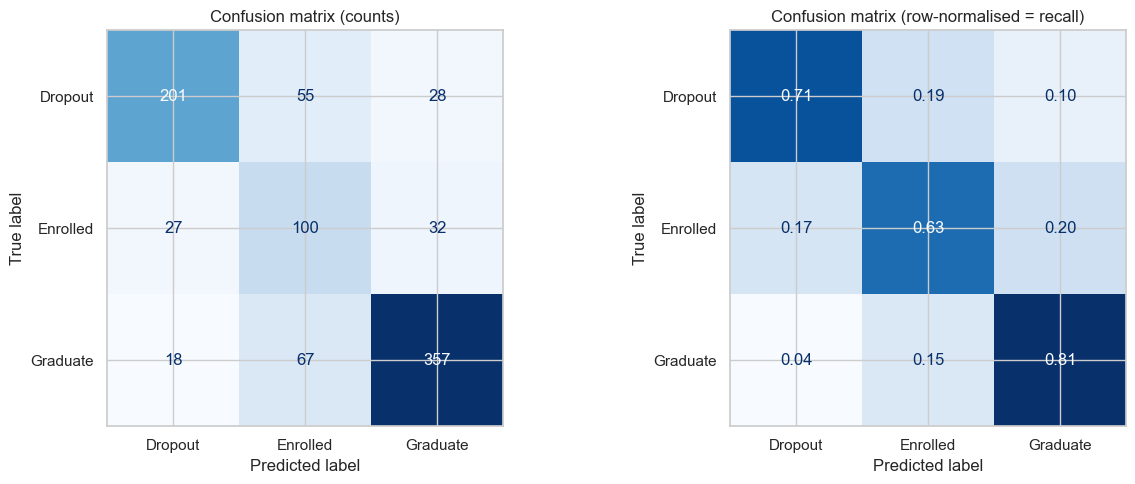

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=CLASS_NAMES, cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title("Confusion matrix (counts)")
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=CLASS_NAMES, cmap="Blues", ax=axes[1],
                                        colorbar=False, normalize="true", values_format=".2f")
axes[1].set_title("Confusion matrix (row-normalised = recall)")
plt.tight_layout()
savefig("07_confusion_matrix")
plt.show()

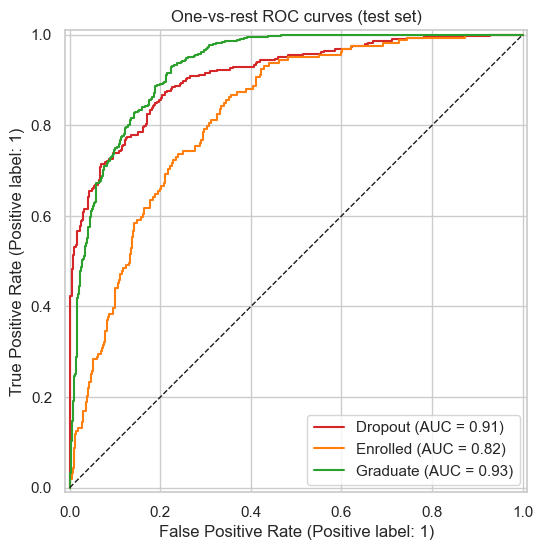

In [17]:
fig, ax = plt.subplots(figsize=(6, 6))
for i, cls in enumerate(CLASS_NAMES):
    RocCurveDisplay.from_predictions((y_test == i).astype(int), y_proba[:, i], name=cls, ax=ax, curve_kwargs={"color": CLASS_COLORS[cls]})
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_title("One-vs-rest ROC curves (test set)")
savefig("08_roc_curves")
plt.show()

## 7. Interpretation — permutation importance

Each raw input column is shuffled 10 times on the test set; the drop in macro-F1 shows how much the model relies on it.
Engineered features (approval rates, grade change) are credited to the raw columns they are computed from.

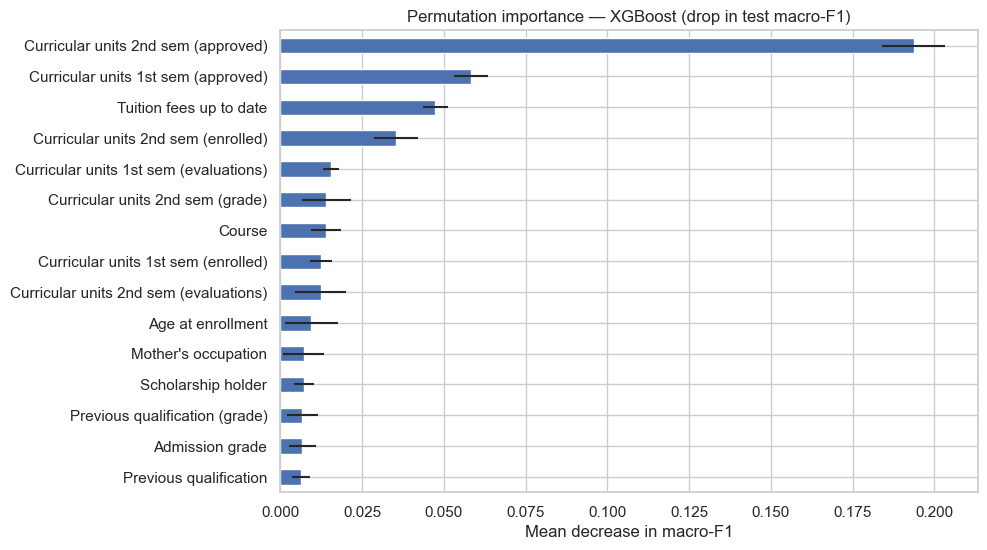

,feature,importance,std
0,Curricular units 2nd sem (approved),0.1936,0.0095
1,Curricular units 1st sem (approved),0.0583,0.0053
2,Tuition fees up to date,0.0474,0.0038
3,Curricular units 2nd sem (enrolled),0.0353,0.0067
4,Curricular units 1st sem (evaluations),0.0155,0.0024
5,Curricular units 2nd sem (grade),0.0140,0.0076
6,Course,0.0140,0.0047
7,Curricular units 1st sem (enrolled),0.0124,0.0033
8,Curricular units 2nd sem (evaluations),0.0123,0.0079
9,Age at enrollment,0.0094,0.0081


In [18]:
perm = permutation_importance(final_model, X_test, y_test, scoring="f1_macro", n_repeats=10,
                              random_state=RANDOM_STATE, n_jobs=-1)
importance = (pd.DataFrame({"feature": X_test.columns, "importance": perm.importances_mean, "std": perm.importances_std})
                .sort_values("importance", ascending=False).reset_index(drop=True))
top = importance.head(15).iloc[::-1]
ax = top.plot.barh(x="feature", y="importance", xerr="std", legend=False, figsize=(9, 6), color="#4c72b0")
ax.set(title=f"Permutation importance — {best_name} (drop in test macro-F1)", xlabel="Mean decrease in macro-F1", ylabel="")
savefig("09_permutation_importance")
plt.show()
importance.head(15).round(4)

## 8. Early-warning variant (no 2nd-semester data)

The main model uses 2nd-semester results, which only exist late in the first year. To see how early a useful warning is possible,
the same model type and hyper-parameters are retrained **without any 2nd-semester columns**.

In [19]:
early_cols = input_columns(early=True)
early_model = build_pipeline(clone(models[best_name]), early=True)
early_model.set_params(**best_search.best_params_)
early_model.fit(X_train[early_cols], y_train, **fit_params(best_name, y_train))
early_pred = early_model.predict(X_test[early_cols])
early_proba = early_model.predict_proba(X_test[early_cols])

early_metrics = {
    "macro_f1": f1_score(y_test, early_pred, average="macro"),
    "balanced_accuracy": balanced_accuracy_score(y_test, early_pred),
    "accuracy": accuracy_score(y_test, early_pred),
    "roc_auc_ovr_macro": roc_auc_score(y_test, early_proba, multi_class="ovr", average="macro"),
}
recalls = recall_score(y_test, y_pred, average=None)
early_recalls = recall_score(y_test, early_pred, average=None)
comparison = pd.DataFrame({
    "Full model (1st + 2nd sem)": {**test_metrics, **{f"recall_{c}": r for c, r in zip(CLASS_NAMES, recalls)}},
    "Early model (1st sem only)": {**early_metrics, **{f"recall_{c}": r for c, r in zip(CLASS_NAMES, early_recalls)}},
})
comparison.round(3)

,Full model (1st + 2nd sem),Early model (1st sem only)
macro_f1,0.705,0.668
balanced_accuracy,0.715,0.675
accuracy,0.744,0.711
roc_auc_ovr_macro,0.888,0.869
recall_Dropout,0.708,0.662
recall_Enrolled,0.629,0.572
recall_Graduate,0.808,0.792


## 9. Save the model and metadata for the app

In [20]:
X_train_raw = X_train.copy()
numeric_inputs = [c for c in X_train_raw.columns if c not in NOMINAL + BINARY]
defaults = {c: float(X_train_raw[c].median()) for c in numeric_inputs}
defaults.update({c: int(X_train_raw[c].mode()[0]) for c in NOMINAL + BINARY})

meta = {
    "model_name": best_name,
    "trained_on": date.today().isoformat(),
    "library_versions": {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
                         "xgboost": xgboost.__version__, "pandas": pd.__version__},
    "class_names": CLASS_NAMES,
    "input_columns": list(X.columns),
    "nominal_columns": NOMINAL,
    "binary_columns": BINARY,
    "defaults": defaults,
    "categories": {c: sorted(int(v) for v in df[c].unique()) for c in NOMINAL},
    "numeric_ranges": {c: [float(df[c].min()), float(df[c].max())] for c in numeric_inputs},
    "best_params": {k.replace("model__", ""): (float(v) if isinstance(v, (float, np.floating)) else
                                               int(v) if isinstance(v, (int, np.integer)) else v)
                    for k, v in best_search.best_params_.items()},
    "cv_results": cv_results.round(4).reset_index().to_dict(orient="records"),
    "tuned_cv_macro_f1": {n: round(float(s.best_score_), 4) for n, s in searches.items()},
    "test_metrics": {k: round(float(v), 4) for k, v in test_metrics.items()},
    "baseline_test_metrics": {k: round(float(v), 4) for k, v in baseline_metrics.items()},
    "test_classification_report": {k: ({m: round(float(x), 4) for m, x in v.items()} if isinstance(v, dict) else round(float(v), 4))
                                   for k, v in report.items()},
    "test_confusion_matrix": pd.crosstab(pd.Series(y_test, name="true"), pd.Series(y_pred, name="pred")).values.tolist(),
    "early_model_test_metrics": {k: round(float(v), 4) for k, v in early_metrics.items()},
    "early_model_recalls": {c: round(float(r), 4) for c, r in zip(CLASS_NAMES, early_recalls)},
    "permutation_importance_top15": importance.head(15).round(4).to_dict(orient="records"),
    "split": {"train_rows": int(len(X_train)), "test_rows": int(len(X_test)), "random_state": RANDOM_STATE},
}

joblib.dump(final_model, MODELS_DIR / "dropout_model.joblib")
(MODELS_DIR / "model_meta.json").write_text(json.dumps(meta, indent=2))
print("Saved:", MODELS_DIR / "dropout_model.joblib")
print("Saved:", MODELS_DIR / "model_meta.json")

Saved: C:\Users\sajja\OneDrive\Desktop\ML-project\dropout_prediction\models\dropout_model.joblib
Saved: C:\Users\sajja\OneDrive\Desktop\ML-project\dropout_prediction\models\model_meta.json


In [21]:
# Sanity check: reload the saved pipeline and predict on raw rows straight from the CSV.
reloaded = joblib.load(MODELS_DIR / "dropout_model.joblib")
sample = load_raw().head(5)
proba = reloaded.predict_proba(sample[meta["input_columns"]])
pd.DataFrame(proba, columns=CLASS_NAMES).assign(predicted=[CLASS_NAMES[i] for i in proba.argmax(1)],
                                                actual=sample[TARGET].values).round(3)

,Dropout,Enrolled,Graduate,predicted,actual
0,0.757,0.077,0.166,Dropout,Dropout
1,0.087,0.024,0.889,Graduate,Graduate
2,0.995,0.005,0.001,Dropout,Dropout
3,0.074,0.198,0.728,Graduate,Graduate
4,0.094,0.138,0.768,Graduate,Graduate


## Conclusion

See the printed metrics above and `models/model_meta.json`. The tuned model clearly beats the majority-class baseline;
*Graduate* and *Dropout* are predicted well, while *Enrolled* (students who are delayed but still studying) is the hardest class
because it sits between the other two. The saved pipeline is served by `app/app.py`.